# Medical Waste Data Analytics

Issue #4 — MED-WASTE-SEGREGATION (Data Analytics & Visualization)

**Input:** `data/processed/medical_waste_cleaned.csv` (output of Issue #3)
**Outputs:** `reports/summary_statistics.csv` and `reports/analytics_summary.md`

All calculations live in `src/analytics.py`; this notebook calls them, shows the results with charts, validates them and writes the report files. Missing values are skipped (never treated as zero), and each table shows how many records it uses.

> The dataset appears to be simulated (see `docs/data_sources.md`), so the results describe this file and demonstrate the workflow. They are not evidence about real hospitals.

**Questions answered**
1. How are waste categories, wards, floors, bins and outcomes distributed?
2. What do the numeric measures (weight, AI confidence, bin fill level) look like?
3. Do segregation errors, weights and alerts differ between waste categories and other attributes?
4. What triggers alerts?
5. Are there trends by day, weekday or hour?

## 0. Setup

In [1]:
from pathlib import Path
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown

ROOT = Path.cwd()
if not (ROOT / "src").exists() and (ROOT.parent / "src").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

from src import analytics as an

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 200)
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 100})
INK, GREY, RED = "#1f1f1f", "#9a9a9a", "#d62728"

## 1. Load the cleaned dataset

In [2]:
df = an.load_data(an.DEFAULT_INPUT)
print("Input:", an.DEFAULT_INPUT.relative_to(ROOT))
display(pd.Series(an.dataset_overview(df), name="value").to_frame())
display(df.head(5))

Input: data/processed/medical_waste_cleaned.csv


,value
records,1482
columns,19
first_date,2026-10-01
last_date,2026-10-30
calendar_days,30
records_with_timestamp,1480
cells_missing_in_analysed_columns,257


,Row_Number,Record_ID,Timestamp,Hospital_Ward,Floor_Number,Waste_Category,Target_Bin_Color,Bin_ID,Weight_Grams,AI_Confidence_Score,Segregation_Status,Bin_Fill_Level_Percentage,Alert_Triggered,Duplicate_Record_ID,Date,Hour,Weekday,Category_Bin_Mismatch,Weight_Outlier
0,2,REC0001,2026-10-07 08:24:00,Emergency,Floor 4,Surgical Waste,Yellow Bin,BIN_02,283.5,0.87,Correctly Segregated,33.0,No,False,2026-10-07,8.0,Wednesday,False,False
1,3,REC0002,2026-10-28 09:33:00,ICU,Floor 4,Used Bandages,Yellow Bin,BIN_04,170.6,0.91,Correctly Segregated,69.0,No,False,2026-10-28,9.0,Wednesday,False,False
2,4,REC0003,2026-10-01 07:05:00,OT,Floor 3,Expired Medications,White Bin,BIN_06,319.9,0.78,Correctly Segregated,40.0,No,False,2026-10-01,7.0,Thursday,False,False
3,5,REC0004,2026-10-18 06:58:00,Emergency,Floor 2,Urine/Body Fluids,Red Bin,BIN_06,644.5,0.88,Misclassified,16.0,Yes,False,2026-10-18,6.0,Sunday,False,False
4,6,REC0005,2026-10-04 14:04:00,Pediatrics,Floor 4,Used Bandages,Yellow Bin,BIN_06,NaN,0.87,Correctly Segregated,53.0,No,False,2026-10-04,14.0,Sunday,False,False


In [3]:
results = an.run_analysis(df)   # every table and test used below
print("Analysis tables computed:", len(results))

Analysis tables computed: 22


## 2. Category counts and distributions

,Waste_Category,count,share_pct
0,Contaminated Recyclable Plastics,89,6.09
1,Expired Medications,86,5.88
2,Blades,85,5.81
3,Surgical Waste,84,5.75
4,Food Waste,83,5.68
5,Non-Infectious Waste,83,5.68
6,Glassware,82,5.61
7,Office Trash,82,5.61
8,Hazardous Chemicals,79,5.40
9,IV Bags/Tubes,77,5.27


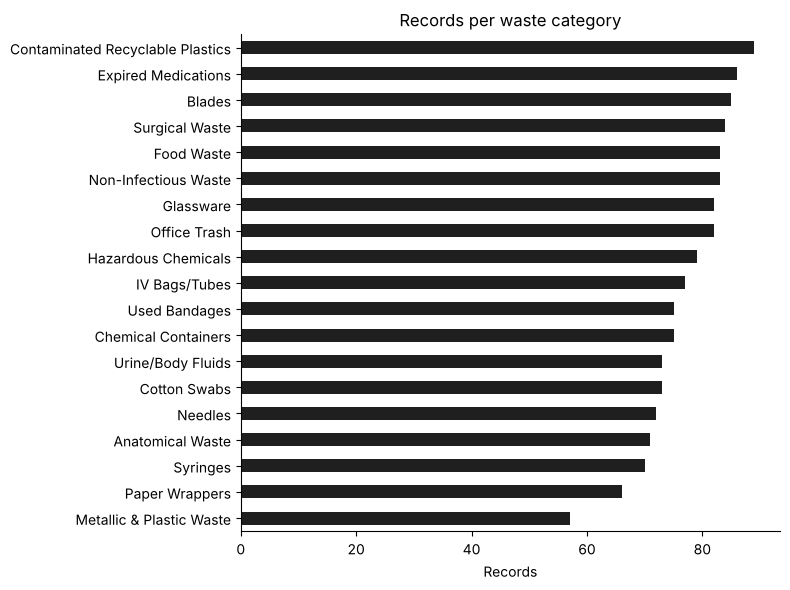

In [4]:
t = results["category_counts"]["Waste_Category"]
display(t)
fig, ax = plt.subplots(figsize=(8, 6))
t.sort_values("count").plot.barh(x="Waste_Category", y="count", ax=ax, color=INK, legend=False)
ax.set_xlabel("Records"); ax.set_ylabel(""); ax.set_title("Records per waste category")
plt.tight_layout(); plt.show()

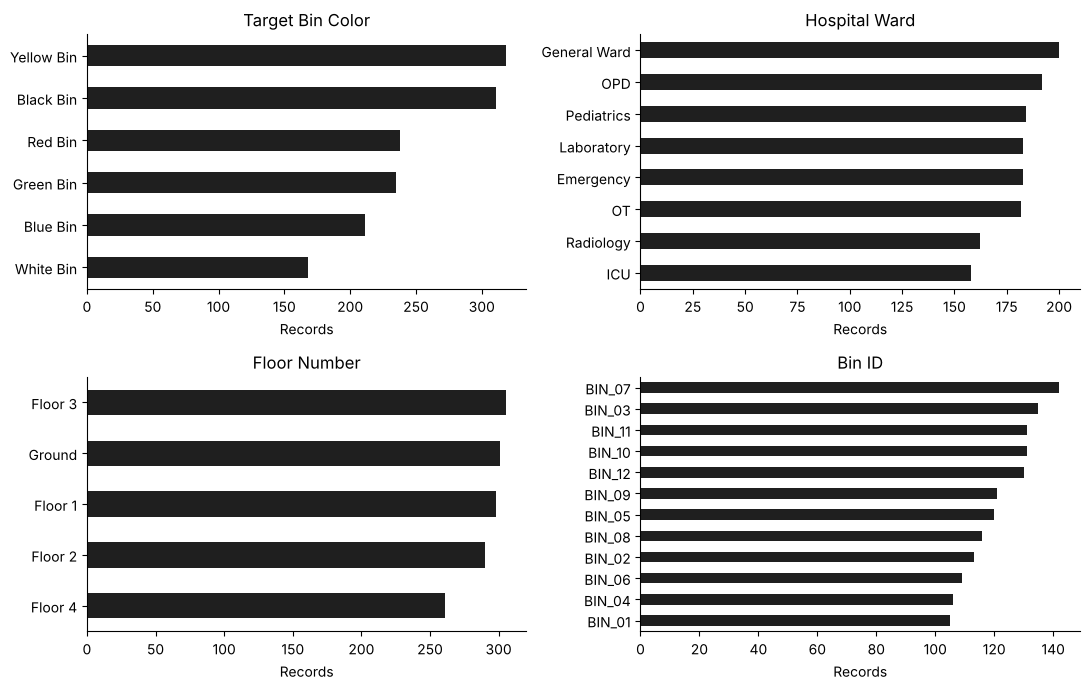

In [5]:
fig, axes = plt.subplots(2, 2, figsize=(11, 7))
for ax, col in zip(axes.ravel(), ["Target_Bin_Color", "Hospital_Ward", "Floor_Number", "Bin_ID"]):
    t = results["category_counts"][col]
    t.sort_values("count").plot.barh(x=col, y="count", ax=ax, color=INK, legend=False)
    ax.set_title(col.replace("_", " ")); ax.set_xlabel("Records"); ax.set_ylabel("")
plt.tight_layout(); plt.show()

In [6]:
display(pd.DataFrame(results["uniformity"]).T[["categories", "n", "min_count", "max_count", "chi2", "p_value"]])
for col in ["Segregation_Status", "Alert_Triggered"]:
    display(results["category_counts"][col])

,categories,n,min_count,max_count,chi2,p_value
Waste_Category,19,1462,57,89,14.749658,0.679079
Target_Bin_Color,6,1481,168,318,68.462525,0.0
Hospital_Ward,8,1444,158,200,7.689751,0.360745
Floor_Number,5,1455,261,305,4.281787,0.369211
Bin_ID,12,1459,105,142,13.397533,0.268139


,Segregation_Status,count,share_pct
0,Correctly Segregated,1365,93.3
1,Misclassified,98,6.7


,Alert_Triggered,count,share_pct
0,No,1144,77.98
1,Yes,323,22.02


Waste categories, wards, floors and bins are spread fairly evenly (p-values above 0.05 against equal shares). Bin colours are unequal because different numbers of waste categories share each colour, for example several categories use Yellow Bin and only two use White Bin.

## 3. Statistical measures

In [7]:
display(results["descriptives"].round(3))

,column,count,missing,mean,median,std,min,q1,q3,max,iqr,skewness,sum
0,Weight_Grams,1451,31,275.568,200.60,265.942,14.3,115.80,333.40,4155.50,217.60,4.069,399849.70
1,AI_Confidence_Score,1460,22,0.845,0.85,0.084,0.7,0.77,0.92,0.99,0.15,-0.014,1233.41
2,Bin_Fill_Level_Percentage,1457,25,52.778,53.00,28.063,0.0,28.00,78.00,100.00,50.00,-0.009,76897.00


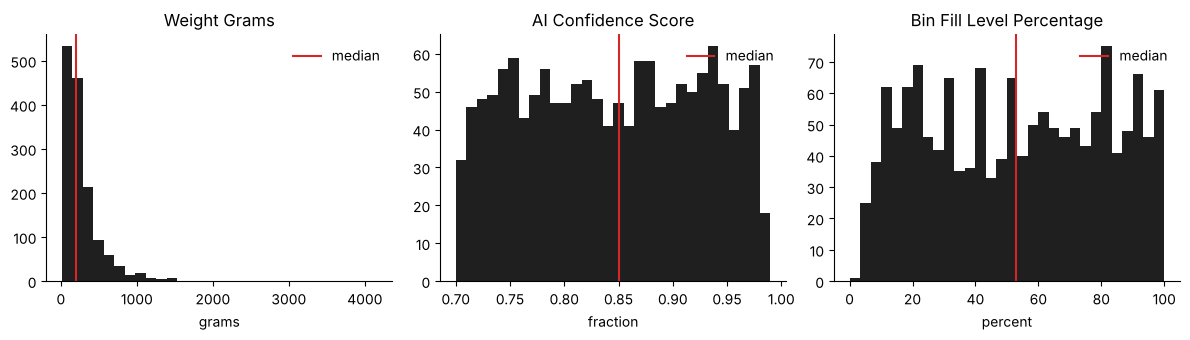

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.5))
for ax, col, unit in zip(axes, an.NUMERIC_COLUMNS, ["grams", "fraction", "percent"]):
    ax.hist(df[col].dropna(), bins=30, color=INK)
    ax.axvline(df[col].median(), color=RED, lw=1.5, label="median")
    ax.set_title(col.replace("_", " ")); ax.set_xlabel(unit); ax.legend(frameon=False)
plt.tight_layout(); plt.show()

In [9]:
display(results["spearman"].round(3))

,Weight_Grams,AI_Confidence_Score,Bin_Fill_Level_Percentage
Weight_Grams,1.000,-0.010,0.046
AI_Confidence_Score,-0.010,1.000,0.045
Bin_Fill_Level_Percentage,0.046,0.045,1.000


Weight is strongly right-skewed (median well below the mean), so medians and rank-based tests are used for weight comparisons. The three numeric columns are not related to each other (all rank correlations near zero).

## 4. Comparisons between categories and attributes

### 4.1 Weight

,Waste_Category,n,mean,median,std,total,share_of_total_pct
0,Syringes,70,286.2,234.5,207.6,20036.1,5.1
1,Chemical Containers,73,324.6,232.8,295.6,23698.1,6.0
2,Anatomical Waste,70,347.5,227.6,384.9,24325.0,6.1
3,Cotton Swabs,73,322.4,220.9,342.8,23534.9,5.9
4,Metallic & Plastic Waste,56,265.6,220.0,265.9,14873.5,3.8
5,Hazardous Chemicals,77,265.2,207.5,217.5,20418.3,5.2
6,Non-Infectious Waste,80,273.9,202.6,242.3,21915.5,5.5
7,Urine/Body Fluids,73,247.4,201.5,186.3,18060.4,4.6
8,Contaminated Recyclable Plastics,86,267.5,201.0,225.4,23007.8,5.8
9,Surgical Waste,83,316.0,200.7,293.6,26224.7,6.6


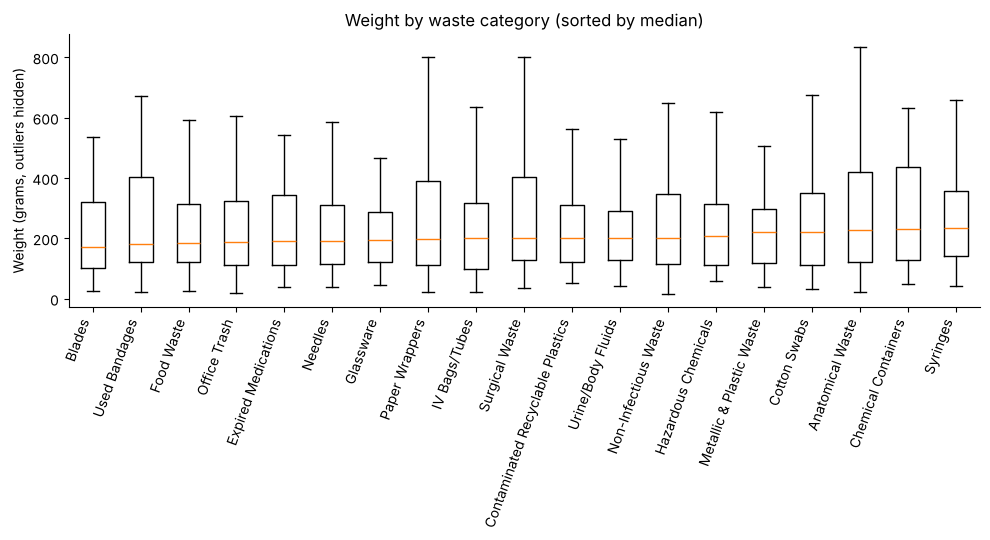

In [10]:
w = results["weight_by_group"]["Waste_Category"]
display(w.round(1))
order = w.sort_values("median")["Waste_Category"]
data = [df.loc[df["Waste_Category"] == c, "Weight_Grams"].dropna() for c in order]
fig, ax = plt.subplots(figsize=(10, 5.5))
ax.boxplot(data, showfliers=False)
ax.set_xticks(range(1, len(order) + 1)); ax.set_xticklabels(order, rotation=70, ha="right")
ax.set_ylabel("Weight (grams, outliers hidden)"); ax.set_title("Weight by waste category (sorted by median)")
plt.tight_layout(); plt.show()

In [11]:
display(pd.DataFrame(results["weight_tests"]).T[["value", "n", "groups", "h", "p_value"]])

,value,n,groups,h,p_value
Waste_Category,Weight_Grams,1431,19,11.255781,0.883189
Hospital_Ward,Weight_Grams,1414,8,0.517418,0.99938
Floor_Number,Weight_Grams,1424,5,0.294706,0.990153
Target_Bin_Color,Weight_Grams,1450,6,3.259997,0.659971
Bin_ID,Weight_Grams,1428,12,14.646339,0.199267


No attribute shows a significant weight difference (all Kruskal-Wallis p-values above 0.05).

### 4.2 Segregation outcome (misclassification)

,value
misclassified,98.00
known_status,1463.00
rate_pct,6.70
ci_low_pct,5.53
ci_high_pct,8.10


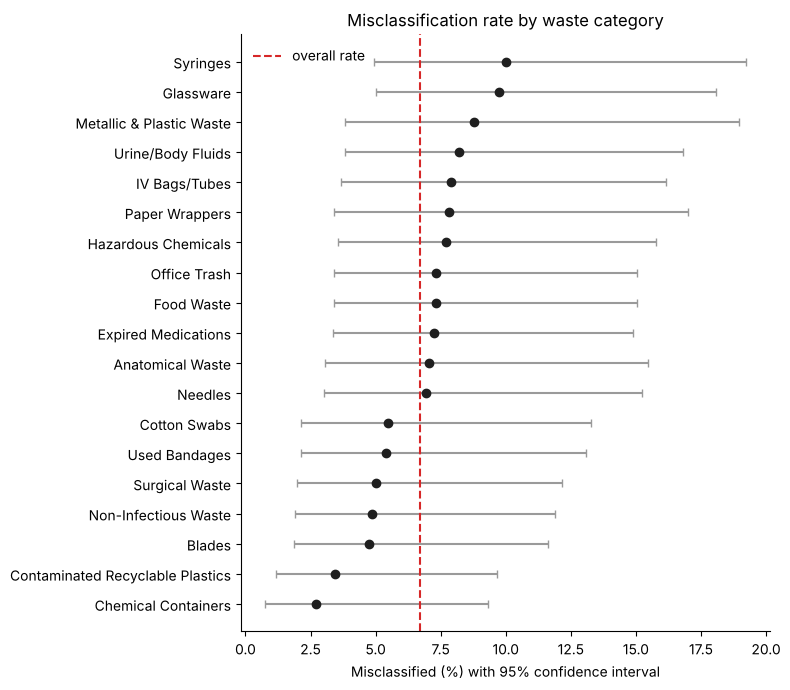

In [12]:
display(pd.Series(results["misclassification"], name="value").to_frame().round(2))
m = results["misclassification_by"]["Waste_Category"].sort_values("rate_pct")
fig, ax = plt.subplots(figsize=(8, 7))
err = [m["rate_pct"] - m["ci_low_pct"], m["ci_high_pct"] - m["rate_pct"]]
ax.errorbar(m["rate_pct"], range(len(m)), xerr=err, fmt="o", color=INK, ecolor=GREY, capsize=3)
ax.axvline(results["misclassification"]["rate_pct"], color=RED, ls="--", label="overall rate")
ax.set_yticks(range(len(m))); ax.set_yticklabels(m["Waste_Category"])
ax.set_xlabel("Misclassified (%) with 95% confidence interval"); ax.legend(frameon=False)
ax.set_title("Misclassification rate by waste category")
plt.tight_layout(); plt.show()

In [13]:
for col in ["Hospital_Ward", "Floor_Number", "Target_Bin_Color", "Bin_ID"]:
    print(col); display(results["misclassification_by"][col].round(1))

Hospital_Ward


,Hospital_Ward,n,misclassified,rate_pct,ci_low_pct,ci_high_pct
0,Emergency,180,15,8.3,5.1,13.3
1,Radiology,159,12,7.5,4.4,12.7
2,OPD,189,13,6.9,4.1,11.4
3,Laboratory,182,12,6.6,3.8,11.2
4,OT,179,11,6.1,3.5,10.7
5,General Ward,199,12,6.0,3.5,10.2
6,ICU,155,9,5.8,3.1,10.7
7,Pediatrics,183,10,5.5,3.0,9.8


Floor_Number


,Floor_Number,n,misclassified,rate_pct,ci_low_pct,ci_high_pct
0,Ground,298,23,7.7,5.2,11.3
1,Floor 4,260,19,7.3,4.7,11.1
2,Floor 1,293,21,7.2,4.7,10.7
3,Floor 3,300,17,5.7,3.6,8.9
4,Floor 2,286,16,5.6,3.5,8.9


Target_Bin_Color


,Target_Bin_Color,n,misclassified,rate_pct,ci_low_pct,ci_high_pct
0,Blue Bin,210,16,7.6,4.7,12.0
1,White Bin,164,12,7.3,4.2,12.4
2,Green Bin,234,17,7.3,4.6,11.3
3,Black Bin,307,22,7.2,4.8,10.6
4,Red Bin,234,15,6.4,3.9,10.3
5,Yellow Bin,313,16,5.1,3.2,8.1


Bin_ID


,Bin_ID,n,misclassified,rate_pct,ci_low_pct,ci_high_pct
0,BIN_10,130,13,10.0,5.9,16.4
1,BIN_07,141,14,9.9,6.0,16.0
2,BIN_01,103,8,7.8,4.0,14.6
3,BIN_12,129,10,7.8,4.3,13.7
4,BIN_06,103,7,6.8,3.3,13.4
5,BIN_04,104,7,6.7,3.3,13.2
6,BIN_11,127,8,6.3,3.2,11.9
7,BIN_02,113,7,6.2,3.0,12.2
8,BIN_03,135,7,5.2,2.5,10.3
9,BIN_08,116,6,5.2,2.4,10.8


In [14]:
tests = pd.DataFrame(results["misclassification_tests"]).T[["n", "chi2", "dof", "p_value", "share_cells_expected_below_5"]]
display(tests.round(3))
print("Attributes with a significant effect (p < 0.05):", [c for c, t in results["misclassification_tests"].items() if t["p_value"] < an.ALPHA] or "none")

,n,chi2,dof,p_value,share_cells_expected_below_5
Waste_Category,1444,8.788362,18,0.964445,0.236842
Hospital_Ward,1426,1.840407,7,0.968143,0.0
Floor_Number,1437,1.825805,4,0.767758,0.0
Target_Bin_Color,1462,1.903359,5,0.862349,0.0
Bin_ID,1440,8.717544,11,0.647946,0.0


Attributes with a significant effect (p < 0.05): none


The confidence intervals overlap the overall rate for every category, and none of the five chi-square tests is significant, so the differences between groups are consistent with chance. Syringes and Glassware have the highest raw rates, but they rest on about 70 to 80 records each.

### 4.3 AI confidence for correct vs misclassified records

,value
n_correct,1344.000
n_misclassified,98.000
median_correct,0.850
median_misclassified,0.830
mean_correct,0.846
mean_misclassified,0.839
u,68801.500
p_value,0.459


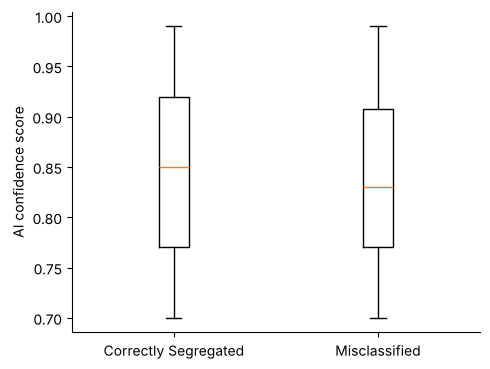

In [15]:
c = results["confidence_by_status"]
display(pd.Series(c, name="value").to_frame().round(3))
fig, ax = plt.subplots(figsize=(5, 3.8))
groups = [df.loc[df["Segregation_Status"] == s, "AI_Confidence_Score"].dropna() for s in ["Correctly Segregated", "Misclassified"]]
ax.boxplot(groups)
ax.set_xticks([1, 2]); ax.set_xticklabels(["Correctly Segregated", "Misclassified"])
ax.set_ylabel("AI confidence score"); plt.tight_layout(); plt.show()

The AI confidence score is almost identical for correct and misclassified items, so it cannot be used to spot errors.

## 5. What triggers alerts?

,value
records_with_alert_known,1467.00
alerts,323.00
alert_rate_pct,22.02
records_used,1424.00
alerts_used,313.00
alerts_misclassified,96.00
alerts_correct_and_fill_above_85,217.00
alerts_correct_and_fill_85_or_below,0.00
misclassified_with_alert_pct,100.00
misclassified_used,96.00


,fill_band,n,alerts,alert_rate_pct
0,0 to 50,677,41,6.1
1,over 50 to 70,296,27,9.1
2,over 70 to 80,158,9,5.7
3,over 80 to 85,73,1,1.4
4,over 85 to 90,78,78,100.0
5,over 90 to 95,84,84,100.0
6,over 95 to 100,77,76,98.7


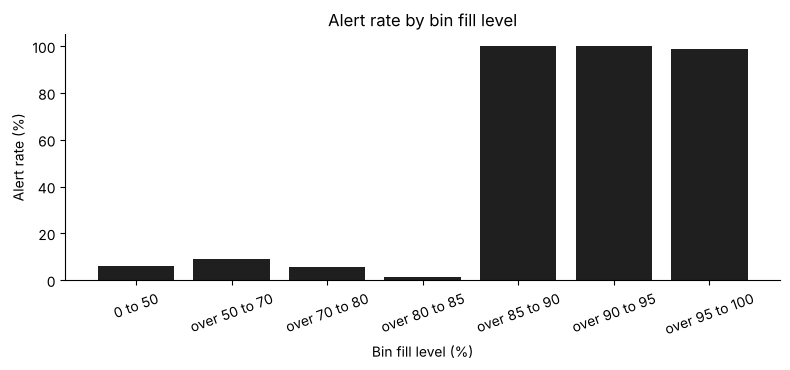

In [16]:
display(pd.Series(results["alerts"], name="value").to_frame().round(2))
b = results["alert_by_fill_band"]
display(b.round(1))
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.bar(b["fill_band"], b["alert_rate_pct"], color=INK)
ax.set_xlabel("Bin fill level (%)"); ax.set_ylabel("Alert rate (%)"); ax.set_title("Alert rate by bin fill level")
plt.xticks(rotation=20); plt.tight_layout(); plt.show()

In [17]:
display(pd.crosstab(df["Alert_Triggered"], df["Segregation_Status"], margins=True))

Segregation_Status,Correctly Segregated,Misclassified,All
Alert_Triggered,,,
No,1128,0,1128
Yes,223,97,320
All,1351,97,1448


Two sources explain the alerts: every misclassified record triggers one, and almost every correctly segregated record in a bin more than 85% full does. Below 85% fill, alerts appear only for misclassified items. This is the pattern in the data, not a documented rule.

In [18]:
display(results["fill_by_bin"].round(1))
print("Fill level differs between bins? Kruskal-Wallis p =", round(results["fill_by_bin_test"]["p_value"], 3))

,Bin_ID,n,mean,median,share_above_85,alert_rate_pct
0,BIN_01,104,55.0,56.5,20.2,27.2
1,BIN_02,112,54.9,57.5,17.0,23.0
2,BIN_03,131,51.4,52.0,13.7,17.3
3,BIN_04,103,55.9,56.0,16.5,20.8
4,BIN_05,118,49.4,50.0,10.2,15.4
5,BIN_06,107,57.2,62.0,20.6,27.4
6,BIN_07,140,49.4,48.0,17.1,26.1
7,BIN_08,114,52.6,54.0,14.0,18.1
8,BIN_09,118,53.1,54.0,16.1,19.2
9,BIN_10,129,54.9,58.0,20.2,26.0


Fill level differs between bins? Kruskal-Wallis p = 0.175


## 6. Time trends

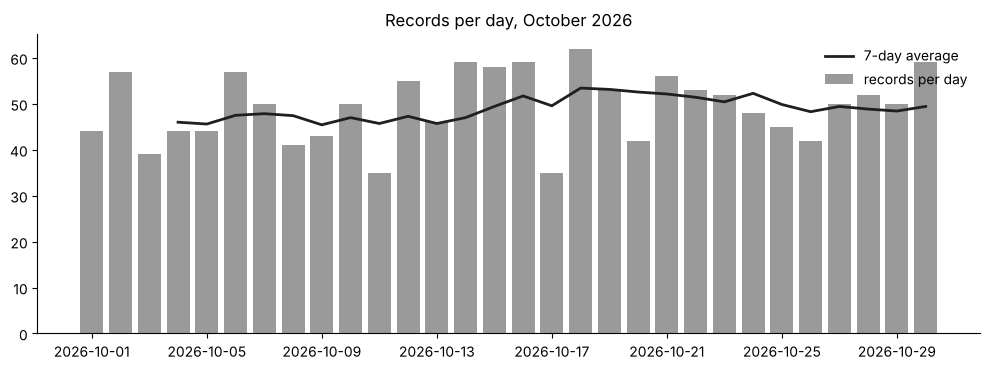

,column,days,slope_per_day,r,p_value
records,records,30,0.183315,0.216948,0.249502
total_weight_g,total_weight_g,30,28.351991,0.075454,0.691897
misclassified_rate_pct,misclassified_rate_pct,30,-0.058922,-0.1472,0.437613


In [19]:
daily = results["daily"]
daily["rolling_7d"] = daily["records"].rolling(7, min_periods=4).mean()
fig, ax = plt.subplots(figsize=(10, 3.8))
ax.bar(daily["Date"], daily["records"], color=GREY, label="records per day")
ax.plot(daily["Date"], daily["rolling_7d"], color=INK, lw=2, label="7-day average")
ax.set_title("Records per day, October 2026"); ax.legend(frameon=False)
plt.tight_layout(); plt.show()
display(pd.DataFrame(results["trends"]).T.round(4))

,Weekday,days,records,records_per_day
0,Monday,4,194,48.50
1,Tuesday,4,195,48.75
2,Wednesday,4,217,54.25
3,Thursday,5,246,49.20
4,Friday,5,270,54.00
5,Saturday,4,172,43.00
6,Sunday,4,186,46.50


Weekday effect? chi-square p = 0.227


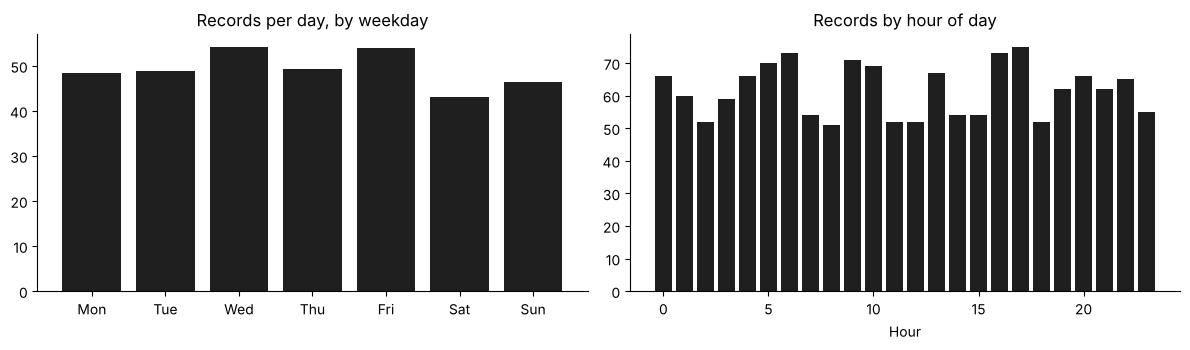

Hourly pattern? chi-square p = 0.423


In [20]:
wk = results["weekday"]
display(wk.round(2))
print("Weekday effect? chi-square p =", round(results["weekday_test"]["p_value"], 3))
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
axes[0].bar(wk["Weekday"].str[:3], wk["records_per_day"], color=INK)
axes[0].set_title("Records per day, by weekday")
hr = results["hourly"]
axes[1].bar(hr["hour"], hr["records"], color=INK)
axes[1].set_title("Records by hour of day"); axes[1].set_xlabel("Hour")
plt.tight_layout(); plt.show()
print("Hourly pattern? chi-square p =", round(results["hourly_test"]["p_value"], 3))

In [21]:
display(results["weekly"].round({"records_per_day": 1, "total_weight_g": 0}))

,week_start,days_covered,records,total_weight_g,records_per_day
0,2026-09-28,4,184,43528.0,46.0
1,2026-10-05,7,320,95276.0,45.7
2,2026-10-12,7,374,103215.0,53.4
3,2026-10-19,7,349,90714.0,49.9
4,2026-10-26,5,253,66605.0,50.6


Weekday totals are divided by the number of each weekday in the window (a month has five of some weekdays and four of others). The first and last calendar weeks are partial. No trend, weekday effect or busy hour is statistically significant.

## 7. Findings and recommendations

In [22]:
report = an.build_report_markdown(df, results)
display(Markdown("### Key findings" + report.split("## 2. Distributions")[0].split("## 1. Key findings")[1]))

### Key findings

1. **Segregation accuracy.** 98 of 1,463 records with a known status were misclassified, a rate of **6.7%** (95% CI 5.5% to 8.1%).
2. **No group stands out.** Misclassification rates differ by ward, floor, waste category, bin colour and bin ID in the raw numbers, but none of these differences is statistically significant (chi-square, smallest p = 0.65). The highest category rate (Syringes, 10.0%, n=70) and the lowest (Chemical Containers, 2.7%, n=74) are within what chance produces with samples this small.
3. **AI confidence does not predict errors.** Median AI confidence is 0.85 for correct records and 0.83 for misclassified ones (no significant difference, Mann-Whitney p = 0.46). A confidence threshold would not catch the misclassifications.
4. **Alerts come from two sources.** 323 of 1,467 records (22.0%) triggered an alert. 100% of misclassified records (n=96) triggered one, and among correctly segregated records the alert rate is 99.5% when the bin is more than 85% full (n=218) versus 0.0% at 85% or below (n=1110). Of the 313 alerts with complete data, 96 follow a misclassification and 217 a nearly full bin. This is a pattern in the data, not a documented rule.
5. **Weights are skewed and similar across groups.** The median record weighs 200.6 g (mean 275.6 g, skewness 4.1). Category medians range only from 170 g to 234 g, and weight shows no significant difference between categories (Kruskal-Wallis p = 0.88), wards (p = 1.00) or floors (p = 0.99).
6. **Activity is steady over time.** Records per day average 49.3 (range 35 to 62). There is no significant trend in daily records (p = 0.25), daily weight (p = 0.69) or daily misclassification rate (p = 0.44), no weekday effect (p = 0.23) and no busy hour (p = 0.42; hourly counts run from 51 to 75).
7. **Bin fill levels.** Mean fill level is 52.8% and 16.4% of readings are above 85%. Fill levels show no significant difference between the 12 bins (Kruskal-Wallis p = 0.17).



In [23]:
display(Markdown("### Recommendations" + report.split("## 6. Recommendations")[1].split("## 7. Limitations")[0]))

### Recommendations

Each one is tied to a finding above. Treat them as design suggestions, since the data is simulated.

1. **Do not rely on AI confidence to catch errors** (finding 3). Add a different safeguard, such as a second check on the item or a periodic manual audit of correctly-labelled items.
2. **Aim to lower the overall misclassification rate, not a single ward or category** (finding 2). The overall rate is 6.7% and no group is reliably worse. Collect more records per category before targeting any one, since the highest raw rates (Syringes) rest on only 70 records.
3. **Use the fill-level alert as the trigger for emptying bins** (finding 4). Almost every alert on a correctly segregated record occurs above 85% fill, and no bin is reliably fuller than the others (finding 7), so one common emptying rule fits all 12 bins better than bin-specific schedules.
4. **Keep alerts for misclassification and full bins separate** (finding 4). Today both produce the same `Alert_Triggered` flag, so staff cannot tell whether to re-sort an item or empty a bin.
5. **Staff for steady demand** (finding 6). No weekday or hour is reliably busier, so no peak-hour staffing is justified by this data.
6. **Collect data over a longer period and from real bins.** One month cannot show seasonal effects, and simulated records cannot show how a real system performs.



## 8. Validate the results against the dataset

In [24]:
checks = an.validate_results(df, results)
display(checks)
assert checks["passed"].all(), "A validation check failed"
print(f"All {len(checks)} checks passed")

,check,passed,details
0,Waste_Category: counts add up to records with ...,True,1462 = 1462
1,Waste_Category: shares add up to 100%,True,sum=100.00
2,Target_Bin_Color: counts add up to records wit...,True,1481 = 1481
3,Target_Bin_Color: shares add up to 100%,True,sum=100.00
4,Hospital_Ward: counts add up to records with a...,True,1444 = 1444
5,Hospital_Ward: shares add up to 100%,True,sum=99.99
6,Floor_Number: counts add up to records with a ...,True,1455 = 1455
7,Floor_Number: shares add up to 100%,True,sum=100.00
8,Bin_ID: counts add up to records with a value,True,1459 = 1459
9,Bin_ID: shares add up to 100%,True,sum=100.00


All 37 checks passed


## 9. Write the report files and confirm they reproduce

In [25]:
stats_path, summary_path, n_checks = an.write_outputs()
saved = pd.read_csv(stats_path)
print("Wrote:", stats_path.relative_to(ROOT), f"({len(saved)} rows)")
print("Wrote:", summary_path.relative_to(ROOT))

# Reproducibility: a second run must give exactly the same statistics
again = an.build_summary_statistics(df)
assert saved.shape == again.shape and np.allclose(saved["value"], again["value"], equal_nan=True)
print("Second run gives identical statistics: True")
display(saved.groupby("section").size().rename("rows").to_frame())

Wrote: reports/summary_statistics.csv (930 rows)
Wrote: reports/analytics_summary.md
Second run gives identical statistics: True


,rows
section,
alert_analysis,14
alert_by_fill_band,21
category_distribution,108
confidence_by_status,8
correlation_spearman,3
fill_level_by_bin,60
fill_level_by_bin_test,2
hourly,24
hourly_test,2


## Summary

* 1,482 cleaned records analysed; missing values skipped, never counted as zero.
* **6.7%** of records were misclassified, with no significant difference between wards, floors, categories, bin colours or bins.
* AI confidence is the same for correct and misclassified items, so it does not flag errors.
* Alerts follow two causes: misclassification and bins more than 85% full.
* Weights are right-skewed and similar across groups.
* Activity is steady across the month: no trend, weekday effect or busy hour.
* Every result passes its validation check, and a second run reproduces the same statistics.